# Algorithms Homework 6

**Choose any three of the six problems below.** Complete three of them, each with its own AI
disclosure, and skip the rest. The problems are independent of one another. Run the setup cells at the
top, and for Problems 2 to 4 also the shared setup that comes before Problem 2.

| Problem | Topic | Course material |
| --- | --- | --- |
| 1 | Branch and bound on a small MILP, node by node | Lecture 25 |
| 2 | MindtPy's four strategies on a convex MINLP, compared with SCIP | Lecture 25 |
| 3 | Options that change outer approximation: initialization, cuts, single tree, MILP solver | Lecture 25 |
| 4 | Outer approximation on a nonconvex MINLP, where it returns wrong answers | Lectures 25 and 26 |
| 5 | Reading the certificate of a global solver, SCIP | Lecture 26 |
| 6 | Short answer, no code | Lectures 25 and 26 |

Problem 1 walks through branch and bound on a mixed-integer linear program small enough to draw. In
Problems 2 to 4 you drive a production MINLP solver, Pyomo's MindtPy, on a problem too big to watch,
and use the theory from Lecture 25 to explain what comes back. Problem 5 uses SCIP, a global solver, for
deterministic global optimization on two classic nonconvex problems.
Notebook [](../8/MINLP-Algorithms.ipynb) implements branch and bound, outer approximation and
generalized Benders decomposition by hand, if you want to see the algorithms in more detail.

In Problems 2 to 4 you will not write an algorithm. You will call one line repeatedly, changing one
option each time:

```python
results = pyo.SolverFactory("mindtpy").solve(
    m, strategy="OA", mip_solver="appsi_highs", nlp_solver="ipopt"
)
```

and then account for the iteration counts, the run times, and, in some cases, the wrong answers.

```{note}
**Optional in Fall 2026.** This assignment builds on Lecture 25 (taught in class) and
Lecture 26 (a recorded, optional lecture this semester). Skipping it uses your dropped homework score; completing it (any three of the six problems) can
replace a lower one. See the [semester calendar](../../org/calendar.md).
```

## Course policies and AI category

Read the [Artificial Intelligence Policy](../../org/syllabus.md#artificial-intelligence-policy) and
[Collaboration Policy and Honor Code](../../org/syllabus.md#collaboration-policy-and-honor-code)
before starting. Assignment-specific directions control. The categories are **No AI**, **AI
permitted after independent work**, and **AI required**.

Unless a problem says otherwise, its category is **AI permitted after independent work**. Spend about
30 minutes on each top-level problem without AI, solution pages, or another person's help, stopping
early if complete. You may consult lecture notes, textbooks, and nonsolution pages of the course
website; bias toward those course sources. Afterward, AI and genuine collaboration, including coding
together, are permitted. Everyone must contribute intellectually, understand the work, and verify it.

At the end of each top-level problem, add a concise **AI disclosure**: approximately
how long the independent attempt took, how far you got, where you became stuck, any AI or collaborative
help used afterward, and how you verified it. If you used no AI, say so. Do not submit prompts or
transcripts. Time estimates help the instructor improve the assignment and are not a speed test.


## Tips and tricks

* **MindtPy's `strategy=` argument selects the algorithm.** `"OA"` is outer approximation (Lecture 25, "Why objective and constraint tangents relax"),
  `"ECP"` is the extended cutting plane method, `"GOA"` is global outer approximation, and `"FP"` is the
  feasibility pump.
* **MindtPy is a *meta*-solver.** It has no numerics of its own: it calls an MILP solver for the master
  problems (`mip_solver=`) and an NLP solver for the subproblems (`nlp_solver=`). Both must be named.
* **Check the termination condition after every solve.** In this assignment the check is one of the main
  findings. At least one strategy below returns an answer and a termination
  condition that is not `optimal`, and a student who skips the check will report a number that is 10 %
  off as if it were the optimum.
* **SCIP is not a MindtPy subsolver.** MindtPy 6.10.1 accepts only a fixed list of MILP solvers
  (HiGHS, CBC, GLPK, Gurobi, CPLEX, GAMS). SCIP is used on its own, as
  `pyo.SolverFactory("scip_direct")`: a branch-and-cut code that solves the whole MINLP, convex or not.
* `results.solver.iterations` holds the number of major iterations for most strategies. Use
  `getattr(results.solver, "iterations", None)` so a missing field does not crash your loop.
* MindtPy is chatty. Wrap the solve in the `quiet()` helper provided below when you want a clean table.
* Wall time is measured with `time.perf_counter()`, and it is noisy at this problem size. Report it to
  two decimals, do not over-interpret differences under about 0.5 s, and re-run before you claim anything
  about speed.

**Reference:** the [MindtPy documentation](https://pyomo.readthedocs.io/en/stable/explanation/solvers/mindtpy.html),
and Biegler, Grossmann & Westerberg (1997) Appendix A, §A.3.2 and §A.3.4.

In [1]:
# This code cell installs packages on Colab

import sys

if "google.colab" in sys.modules:
    !wget "https://raw.githubusercontent.com/ndcbe/optimization/main/notebooks/helper.py"
    import helper

    helper.easy_install()
else:
    sys.path.insert(0, "../")
    import helper

helper.set_plotting_style()

In [2]:
import contextlib
import io
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyomo.environ as pyo

rng = np.random.default_rng(seed=0)


@contextlib.contextmanager
def quiet():
    """Swallow a solver's chatter so a loop can print a clean table."""
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        yield buf

## Problem 1. Branch and bound on a small MILP

Before handing the work to a production solver, watch branch and bound decide every node of a problem
small enough to draw. A shop makes two products in whole units: each unit of product 1 earns \$5 and each
unit of product 2 earns \$4. Machine time and labor limit production:

$$
\begin{aligned}
\min_{x_1, x_2} \quad & z = -5x_1 - 4x_2 \qquad (\text{i.e. maximize profit } 5x_1 + 4x_2) \\
\mathrm{s.t.} \quad & 6x_1 + 4x_2 \le 23 \quad (\text{machine hours}) \\
& x_1 + 2x_2 \le 7 \quad (\text{labor hours}) \\
& x_1, x_2 \ge 0, \quad x_1, x_2 \in \mathbb{Z}.
\end{aligned}
$$

We write it as a minimization so the closing rules match Lecture 25, "Why a node can be closed": with incumbent value $U$ (the best
integer-feasible objective found so far) and a node's relaxation value $\ell_j$, a node is closed when

1. its linear relaxation is **infeasible**;
2. its relaxation optimum is **integer**, which updates the incumbent if $\ell_j < U$; or
3. its **bound** satisfies $\ell_j \ge U$, so no descendant can beat the incumbent.

Otherwise we **branch** on a fractional variable $x_i = \bar{x}_i$, creating the children
$x_i \le \lfloor \bar{x}_i \rfloor$ and $x_i \ge \lceil \bar{x}_i \rceil$.

The code below is complete. It solves each node's linear relaxation with HiGHS, chooses the most
fractional variable, and explores the tree depth first, taking the $\le$ child first. Run it and read the
log, then answer the questions.

In [3]:
### Worked branch and bound (provided)
import math


def solve_node_lp(lb, ub):
    """Solve the linear relaxation with bounds lb <= x <= ub.

    Returns (x, z) at the optimum, or (None, None) if the relaxation is infeasible.
    """
    m = pyo.ConcreteModel()
    m.I = pyo.Set(initialize=[1, 2])
    m.x = pyo.Var(m.I, domain=pyo.NonNegativeReals, bounds=lambda m, i: (lb[i], ub[i]))
    m.obj = pyo.Objective(expr=-5 * m.x[1] - 4 * m.x[2])
    m.machine = pyo.Constraint(expr=6 * m.x[1] + 4 * m.x[2] <= 23)
    m.labor = pyo.Constraint(expr=m.x[1] + 2 * m.x[2] <= 7)
    res = pyo.SolverFactory("appsi_highs").solve(m, load_solutions=False)
    tc = res.solver.termination_condition
    if tc == pyo.TerminationCondition.infeasible:
        return None, None
    assert pyo.check_optimal_termination(res), f"unexpected LP status: {tc}"
    m.solutions.load_from(res)
    return {i: pyo.value(m.x[i]) for i in m.I}, pyo.value(m.obj)


def branch_and_bound(order="depth", tol=1e-7, verbose=True):
    """Branch and bound with LP relaxations.

    order: "depth" (last created node first, <= child first) or "best"
           (open node with the smallest parent bound first)
    Returns the incumbent (x, U) and a list of node records.
    """
    # each open node: (id, parent id, lower bounds, upper bounds, parent's relaxation value)
    open_nodes = [(0, None, {1: 0, 2: 0}, {1: None, 2: None}, -math.inf)]
    U, x_inc, log, next_id = math.inf, None, [], 1
    while open_nodes:
        if order == "best":
            open_nodes.sort(key=lambda node: node[4], reverse=True)
        node_id, parent, lb, ub, _ = open_nodes.pop()
        x, z = solve_node_lp(lb, ub)
        bounds = ", ".join(
            [f"x{i} >= {lb[i]}" for i in (1, 2) if lb[i] > 0]
            + [f"x{i} <= {ub[i]}" for i in (1, 2) if ub[i] is not None]
        ) or "root"
        if x is None:
            action = "closed: infeasible"
        elif z >= U - tol:
            action = f"closed: bound ({z:.3f} >= U = {U:.3f})"
        else:
            frac = [i for i in (1, 2) if abs(x[i] - round(x[i])) > tol]
            if not frac:
                U, x_inc = z, {i: round(x[i]) for i in (1, 2)}
                action = f"closed: integer -> new incumbent U = {U:.3f}"
            else:
                # most fractional variable: fractional part closest to 1/2
                i = min(frac, key=lambda i: abs(x[i] - math.floor(x[i]) - 0.5))
                f = math.floor(x[i])
                down_ub, up_lb = dict(ub), dict(lb)
                down_ub[i], up_lb[i] = f, f + 1
                down = (next_id, node_id, dict(lb), down_ub, z)
                up = (next_id + 1, node_id, up_lb, dict(ub), z)
                next_id += 2
                # depth first: push the >= child, then the <= child, so <= is explored first
                open_nodes += [up, down]
                action = f"branch on x{i}: node {down[0]} (x{i} <= {f}), node {up[0]} (x{i} >= {f + 1})"
        log.append({"node": node_id, "parent": parent, "bounds": bounds, "x": x, "z": z, "action": action})
        if verbose:
            xs = "infeasible" if x is None else f"({x[1]:.3f}, {x[2]:.3f})"
            zs = "" if z is None else f"{z:8.3f}"
            print(f"node {node_id:2d}  [{bounds:24s}]  x = {xs:16s} z = {zs:8s}  {action}")
    return x_inc, U, log


x_bb, U_bb, log_bb = branch_and_bound(order="depth")
print(f"\nOptimum: x = ({x_bb[1]}, {x_bb[2]}), z = {U_bb:.0f}, profit = ${-U_bb:.0f}; nodes solved: {len(log_bb)}")

node  0  [root                    ]  x = (2.250, 2.375)   z =  -20.750  branch on x2: node 1 (x2 <= 2), node 2 (x2 >= 3)


node  1  [x2 <= 2                 ]  x = (2.500, 2.000)   z =  -20.500  branch on x1: node 3 (x1 <= 2), node 4 (x1 >= 3)


node  3  [x1 <= 2, x2 <= 2        ]  x = (2.000, 2.000)   z =  -18.000  closed: integer -> new incumbent U = -18.000


node  4  [x1 >= 3, x2 <= 2        ]  x = (3.000, 1.250)   z =  -20.000  branch on x2: node 5 (x2 <= 1), node 6 (x2 >= 2)


node  5  [x1 >= 3, x2 <= 1        ]  x = (3.167, 1.000)   z =  -19.833  branch on x1: node 7 (x1 <= 3), node 8 (x1 >= 4)


node  7  [x1 >= 3, x1 <= 3, x2 <= 1]  x = (3.000, 1.000)   z =  -19.000  closed: integer -> new incumbent U = -19.000


node  8  [x1 >= 4, x2 <= 1        ]  x = infeasible       z =           closed: infeasible


node  6  [x1 >= 3, x2 >= 2, x2 <= 2]  x = infeasible       z =           closed: infeasible


node  2  [x2 >= 3                 ]  x = (1.000, 3.000)   z =  -17.000  closed: bound (-17.000 >= U = -19.000)

Optimum: x = (3, 1), z = -19, profit = $19; nodes solved: 9


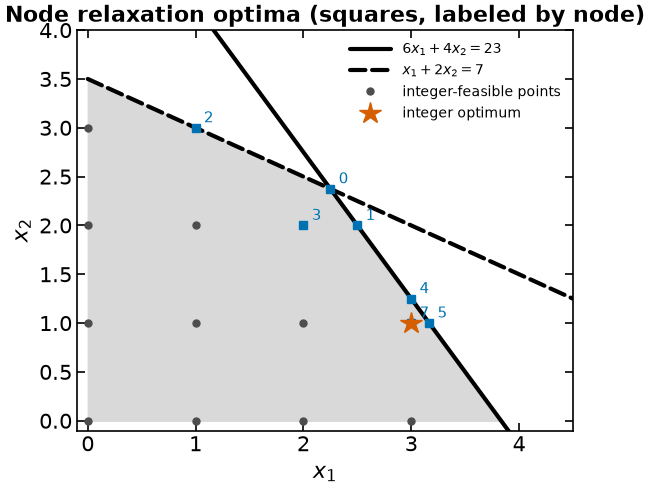

In [4]:
### Plot the relaxations (provided)
fig, ax = plt.subplots(figsize=(6.4, 5.2))
x1 = np.linspace(0, 4.5, 200)
ax.plot(x1, (23 - 6 * x1) / 4, color="k", label="$6x_1 + 4x_2 = 23$")
ax.plot(x1, (7 - x1) / 2, color="k", linestyle="--", label="$x_1 + 2x_2 = 7$")
ax.fill_between(x1, 0, np.minimum((23 - 6 * x1) / 4, (7 - x1) / 2),
                where=np.minimum((23 - 6 * x1) / 4, (7 - x1) / 2) >= 0, color="0.85")
pts = [(a, b) for a in range(6) for b in range(5) if 6 * a + 4 * b <= 23 and a + 2 * b <= 7]
ax.plot(*zip(*pts), "o", color="0.3", markersize=5, label="integer-feasible points")
for rec in log_bb:
    if rec["x"] is not None:
        ax.plot(rec["x"][1], rec["x"][2], "s", color="#0072B2", markersize=6)
        ax.annotate(str(rec["node"]), (rec["x"][1], rec["x"][2]), textcoords="offset points",
                    xytext=(6, 4), fontsize=11, color="#0072B2")
ax.plot(x_bb[1], x_bb[2], "*", color="#D55E00", markersize=16, label="integer optimum")
ax.set_xlim(-0.1, 4.5)
ax.set_ylim(-0.1, 4.0)
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title("Node relaxation optima (squares, labeled by node)")
ax.legend(loc="upper right", fontsize=10)
plt.show()

**Question 1a. The root.** Verify the root relaxation by hand: which constraints are active, and what
are $\mathbf{x}$ and $z$? Round the root solution to the nearest integer point. Is it feasible? Is it
optimal? What, if anything, does it tell you about $U$?

**Answer:**

| | $\mathbf{x}$ | $z$ | Feasible? | Optimal? |
| --- | --- | --- | --- | --- |
| root relaxation |  |  |  |  |
| rounded point |  |  |  |  |

**Question 1b. Closing rules.** For every closed node in the log, name the rule that closed it. Node 2's
relaxation optimum is already integer, yet the log closes it by bound rather than recording a new
incumbent. Why is that correct? What would have happened if the search had explored the $\ge$ child
of the root first?

**Answer:**

| Node | Closing rule | Why |
| --- | --- | --- |
| 3 |  |  |
| 7 |  |  |
| 8 |  |  |
| 6 |  |  |
| 2 |  |  |

**Question 1c. The gap during the search.** Immediately after node 7 is solved, what is the incumbent
$U$, which nodes are still open, and what is the best lower bound on the optimal value? Express the
remaining gap $U - \min_j \ell_j$ in dollars of profit.

**Answer:**

| Incumbent $U$ | Open nodes | Best lower bound | Gap (dollars of profit) |
| --- | --- | --- | --- |
|  |  |  |  |

**Question 1d. Search order.** Re-run with `branch_and_bound(order="best")`. How many nodes does it
solve, and in what order? Which order would you prefer if you had to stop early and needed a good
feasible answer, and which if you needed a tight bound?

In [ ]:
# Add your solution here

**Answer:**

| Search order | Nodes solved | Order of nodes | Prefer it when... |
| --- | --- | --- | --- |
| depth first |  |  |  |
| best first |  |  |  |

### AI disclosure

Approximately how long was your independent attempt?

How far did you get? where did you get stuck?

What AI or collaborative help did you use afterward, and how did you verify it?

If you used no AI, answer "not applicable".

## Shared setup for Problems 2, 3 and 4: the retrofit model

Run the cells in this section before Problems 2 to 4. (Problem 4 uses only the materials table and the
constants.) You do not need them for Problems 1, 5 and 6.

A whole-building insulation retrofit. Four wall assemblies (three walls and a roof) are to be insulated
from a catalogue of eight materials. This is the notebook's single-wall problem with three things added,
each of which makes the binary structure hard:

* **Per-assembly layer choice.** $y_{w,n} = 1$ if material $n$ is installed on assembly $w$, with
  thickness $x_{w,n} \le t^{\max}_n y_{w,n}$.
* **A stocking decision.** $z_n = 1$ if material $n$ is used *anywhere*. Each stocked material costs a
  fixed crew/logistics charge, so the optimizer is pushed toward using few materials on many walls.
  The constraint $y_{w,n} \le z_n$ couples the assemblies.
* **A capital budget.** Total installed cost is capped, which is what makes this a constrained
  combinatorial problem rather than four independent ones.

$$
\begin{aligned}
\min_{\mathbf{x},\mathbf{y},\mathbf{z}} \quad
  & \sum_{w} A_w \left[ \frac{\alpha}{R_w} + \beta \sum_n \left( a_n y_{w,n} + b_n x_{w,n} \right) \right]
    + \beta \, \kappa \sum_n z_n \\
\text{s.t.} \quad
  & R_w = R_{0,w} + \sum_n \frac{x_{w,n}}{k_n} && \forall w \\
  & x_{w,n} \le t^{\max}_n \, y_{w,n},
    \qquad y_{w,n} \le z_n && \forall w, n \\
  & \sum_n x_{w,n} \le t^{\max}_w && \forall w \\
  & \sum_{w} A_w \sum_n \left( a_n y_{w,n} + b_n x_{w,n} \right) + \kappa \sum_n z_n \le \mathcal{B} \\
  & \mathbf{x} \ge \mathbf{0}, \qquad \mathbf{y}, \mathbf{z} \in \{0,1\}
\end{aligned}
$$

The objective is **convex** for fixed $\mathbf{y}$: $\alpha/R_w$ is convex in $\mathbf{x}$ because $R_w$ is affine and
positive, and everything else is linear. Every constraint is linear. So this is a convex MINLP, and outer
approximation and generalized Benders both apply with their guarantees intact. Problem 4 breaks that on
purpose.

There are $4 \times 8 + 8 = 40$ binary variables here, so complete enumeration would need $2^{40} \approx
10^{12}$ NLP solves.

In [6]:
# k: thermal conductivity [W/m/K]; a: fixed installation cost [$/m^2];
# b: installed material cost [$/m^3]; tmax: largest available thickness [m]
materials = pd.DataFrame(
    {
        "Fiberglass batt": {"k": 0.040, "a": 4.0, "b": 60.0, "tmax": 0.06},
        "Mineral wool": {"k": 0.030, "a": 5.0, "b": 150.0, "tmax": 0.06},
        "Rigid foam (low R)": {"k": 0.030, "a": 8.0, "b": 120.0, "tmax": 0.05},
        "Rigid foam (high R)": {"k": 0.015, "a": 8.0, "b": 180.0, "tmax": 0.05},
        "Aerogel blanket": {"k": 0.013, "a": 12.0, "b": 900.0, "tmax": 0.02},
        "Cellulose fill": {"k": 0.038, "a": 3.0, "b": 45.0, "tmax": 0.08},
        "Polyiso board": {"k": 0.022, "a": 7.0, "b": 160.0, "tmax": 0.05},
        "Vacuum panel": {"k": 0.007, "a": 25.0, "b": 2500.0, "tmax": 0.015},
    }
).T

# area [m^2]; R0: resistance of the structural elements [m^2 K / W];
# tmax: cavity depth available on that assembly [m]
assemblies = pd.DataFrame(
    {
        "North wall": {"area": 40.0, "R0": 2.0, "tmax": 0.15},
        "East wall": {"area": 25.0, "R0": 1.6, "tmax": 0.12},
        "South wall": {"area": 40.0, "R0": 2.4, "tmax": 0.10},
        "Roof": {"area": 60.0, "R0": 3.0, "tmax": 0.25},
    }
).T

ALPHA = 60.0  # annualized energy cost per unit U   [$ K / W / m^2]
BETA = 0.05  # equivalent annual cost factor on capital
CREW = 150.0  # fixed crew/logistics charge per material stocked [$]
BUDGET = 900.0  # capital budget [$]

display(materials)
display(assemblies)

,k,a,b,tmax
Fiberglass batt,0.040,4.0,60.0,0.060
Mineral wool,0.030,5.0,150.0,0.060
Rigid foam (low R),0.030,8.0,120.0,0.050
Rigid foam (high R),0.015,8.0,180.0,0.050
Aerogel blanket,0.013,12.0,900.0,0.020
Cellulose fill,0.038,3.0,45.0,0.080
Polyiso board,0.022,7.0,160.0,0.050
Vacuum panel,0.007,25.0,2500.0,0.015


,area,R0,tmax
North wall,40.0,2.0,0.15
East wall,25.0,1.6,0.12
South wall,40.0,2.4,0.10
Roof,60.0,3.0,0.25


In [7]:
def build_retrofit_minlp(budget=BUDGET):
    """Build the whole-building insulation retrofit MINLP.

    Arguments:
        budget: capital budget on installed cost [$]

    Returns:
        a Pyomo ConcreteModel
    """
    m = pyo.ConcreteModel("insulation retrofit MINLP")
    m.N = pyo.Set(initialize=list(materials.index))
    m.W = pyo.Set(initialize=list(assemblies.index))

    m.x = pyo.Var(m.W, m.N, domain=pyo.NonNegativeReals, bounds=(0, 0.3))
    m.y = pyo.Var(m.W, m.N, domain=pyo.Binary)  # material n installed on assembly w
    m.z = pyo.Var(m.N, domain=pyo.Binary)  # material n stocked at all

    @m.Constraint(m.W, m.N)
    def layer_available(m, w, n):
        return m.x[w, n] <= materials.loc[n, "tmax"] * m.y[w, n]

    @m.Constraint(m.W, m.N)
    def stocked(m, w, n):
        return m.y[w, n] <= m.z[n]

    @m.Constraint(m.W)
    def thickness_budget(m, w):
        # [m] cavity depth available on that assembly
        return sum(m.x[w, n] for n in m.N) <= assemblies.loc[w, "tmax"]

    @m.Constraint()
    def capital_budget(m):
        # [$] installed cost, before annualization
        return (
            sum(
                assemblies.loc[w, "area"]
                * (
                    materials.loc[n, "a"] * m.y[w, n]
                    + materials.loc[n, "b"] * m.x[w, n]
                )
                for w in m.W
                for n in m.N
            )
            + CREW * sum(m.z[n] for n in m.N)
            <= budget
        )

    @m.Objective(sense=pyo.minimize)
    def cost(m):
        total = 0
        for w in m.W:
            # [m^2 K / W] series resistance of the assembly
            R = assemblies.loc[w, "R0"] + sum(
                m.x[w, n] / materials.loc[n, "k"] for n in m.N
            )
            total += assemblies.loc[w, "area"] * (
                ALPHA / R
                + BETA
                * sum(
                    materials.loc[n, "a"] * m.y[w, n]
                    + materials.loc[n, "b"] * m.x[w, n]
                    for n in m.N
                )
            )
        total += BETA * CREW * sum(m.z[n] for n in m.N)
        return total

    return m


def report(m, label):
    """Print the stocked materials and the layer schedule of a solved model."""
    print(f"{label}: annualized cost = {pyo.value(m.cost):.4f} $/yr")
    print(f"  stocked: {[n for n in m.N if pyo.value(m.z[n]) > 0.5]}")
    for w in m.W:
        layers = {
            n: round(pyo.value(m.x[w, n]), 4) for n in m.N if pyo.value(m.y[w, n]) > 0.5
        }
        print(f"  {w:12s} {layers}")

### The reference answer

Before benchmarking anything, get an answer you trust. **bonmin** is a dedicated MINLP solver (it
implements NLP-based branch and bound and outer approximation, among others) and it is exact for convex
problems, which this one is. Every MindtPy run in Problems 2 and 3 is measured against this number.

In [8]:
m_ref = build_retrofit_minlp()
t0 = time.perf_counter()
results = pyo.SolverFactory("bonmin").solve(m_ref)
t_ref = time.perf_counter() - t0

assert pyo.check_optimal_termination(
    results
), f"bonmin failed: {results.solver.termination_condition}"

Z_REF = pyo.value(m_ref.cost)
report(m_ref, "bonmin")
print(f"  wall time = {t_ref:.2f} s")

bonmin: annualized cost = 2764.3022 $/yr
  stocked: ['Cellulose fill']
  North wall   {'Cellulose fill': 0.08}
  East wall    {'Cellulose fill': 0.08}
  South wall   {'Cellulose fill': 0.08}
  Roof         {}
  wall time = 0.51 s


### The benchmark helper (provided)

`benchmark(strategy, **options)` builds a fresh model, solves it with MindtPy under the given strategy,
and returns a dictionary with the termination condition, objective, major iterations, wall time and gap
versus `reference`. Options such as `init_strategy=` or `mip_solver=` pass straight through to MindtPy.
If the solve raises an exception, it returns the exception type and message in place of the numbers, so
a loop over strategies keeps going.

In [9]:
def benchmark(strategy, model_builder=build_retrofit_minlp, reference=None, **options):
    """Run one MindtPy strategy on a fresh model and summarize the outcome.

    Arguments:
        strategy: MindtPy strategy string, e.g. "OA"
        model_builder: zero-argument callable returning a fresh ConcreteModel
        reference: objective value to compare against, or None
        **options: extra keyword arguments passed to MindtPy

    Returns:
        a dict of results; on failure, the exception type and message
    """
    label = strategy + (
        "  (" + ", ".join(f"{k}={v}" for k, v in options.items()) + ")"
        if options
        else ""
    )
    m = model_builder()
    t0 = time.perf_counter()
    try:
        with quiet():
            results = pyo.SolverFactory("mindtpy").solve(
                m,
                strategy=strategy,
                **{"mip_solver": "appsi_highs", "nlp_solver": "ipopt", **options},
            )
    except Exception as exc:
        return {
            "strategy": label,
            "termination": f"{type(exc).__name__}",
            "objective": np.nan,
            "iterations": np.nan,
            "time [s]": np.nan,
            "gap vs bonmin": np.nan,
            "note": str(exc).splitlines()[0][:70],
        }
    elapsed = time.perf_counter() - t0

    obj = pyo.value(m.cost, exception=False)
    tc = results.solver.termination_condition
    return {
        "strategy": label,
        "termination": str(tc),
        "objective": obj,
        "iterations": getattr(results.solver, "iterations", np.nan),
        "time [s]": elapsed,
        "gap vs bonmin": (
            obj - reference if (reference is not None and obj is not None) else np.nan
        ),
        "note": "" if pyo.check_optimal_termination(results) else "NOT optimal",
    }


## Problem 2. MindtPy's strategies on a convex MINLP

Solve the retrofit model with MindtPy's **outer approximation** strategy, using `appsi_highs` for the
master MILPs and `ipopt` for the NLP subproblems.

Then, before printing anything:

1. Assert that the termination condition is optimal.
2. Assert that the objective agrees with `Z_REF` to within $10^{-3}$.

Print the objective, the number of major iterations, and the wall time.

In [ ]:
m1 = build_retrofit_minlp()

# Add your solution here

**Question 2a.** Outer approximation solves one NLP and one MILP per major iteration. Look at the
iteration count you just printed. How many NLP solves is that, and how does it compare with the
$2^{40}$ that complete enumeration would need? What is doing the work of eliminating the rest?

**Answer:**

**The strategy sweep.** MindtPy 6.10.1 advertises four strategies: `"OA"`, `"ECP"`, `"GOA"` and `"FP"`.
Try all four on the same model with the provided `benchmark` function, using `reference=Z_REF`, and
display the table.

Do not assume they all work. One of them requires a compiled library that is not part of this course
environment. `benchmark` catches the exception, records it, and keeps going, so one failed strategy does
not stop the loop.

In [ ]:
# Add your solution here

**Question 2b. GOA.** One row failed. Report the exception, then explain in one sentence what MindtPy was
trying to do when it failed, and why global outer approximation needs machinery that outer approximation
does not. The following cell will help you diagnose it.

In [12]:
from pyomo.contrib.mcpp.pyomo_mcpp import mcpp_available

print("MC++ library available:", mcpp_available())

MC++ library available: False


**Answer:**

**Question 2c. FP.** Report the feasibility pump row's
termination condition and its objective. Is the objective feasible? Is it optimal? Would
`pyo.check_optimal_termination` have caught it?

Then explain, in terms of the upper and lower bounds $U$ and $L$ of Lecture 25 ("Integer exclusions and the outer-approximation loop"), why the feasibility pump can
never return a proof of optimality no matter how long you run it.

**Answer:**

| Termination condition | Objective | Gap vs bonmin | Feasible? | Optimal? | Caught by `check_optimal_termination`? |
| --- | --- | --- | --- | --- | --- |
|  |  |  |  |  |  |

**Question 2d. ECP.** The extended cutting plane method reaches an objective close to, but not exactly,
bonmin's, and it does so much faster than OA. Report both numbers. Then explain the mechanism: what does
ECP do at each iteration that OA does *not* do, and how does that account for both the speed and the
residual error?

**Answer:**

| | Objective | Major iterations | Time [s] |
| --- | --- | --- | --- |
| OA |  |  |  |
| ECP |  |  |  |

**Question 2e. SCIP.** MindtPy decomposes the problem into MILPs and NLPs. SCIP does not: it runs one
branch-and-cut tree over the whole MINLP, building linear relaxations of the nonlinear terms as it
goes. Solve the retrofit model with `pyo.SolverFactory("scip_direct")`, check its termination condition,
and add a row for it to your table (objective, gap vs bonmin, time). Then explain what SCIP's answer
certifies that ECP's does not, and why SCIP needs no convexity assumption to do so.

In [ ]:
# Add your solution here

**Answer:**

| | Termination | Objective | Gap vs bonmin | Time [s] |
| --- | --- | --- | --- | --- |
| SCIP |  |  |  |  |

### AI disclosure

Approximately how long was your independent attempt?

How far did you get? where did you get stuck?

What AI or collaborative help did you use afterward, and how did you verify it?

If you used no AI, answer "not applicable".

## Problem 3. Toggling outer approximation

`strategy="OA"` names a family of algorithms. Three options change it substantially, and a
fourth changes only the software underneath it.

**(a) `init_strategy=`** sets where the first $\mathbf{y}^{1}$ comes from. In the notebook we started from a
deliberately poor guess (aerogel alone) and watched it cost an iteration. MindtPy offers

| value | what it does |
| --- | --- |
| `"rNLP"` | solve the fully relaxed NLP (integrality dropped) and round (the default) |
| `"max_binary"` | maximize the sum of the binaries subject to the linear constraints |
| `"initial_binary"` | use the values already stored in the model's binary variables |
| `"FP"` | run the feasibility pump from Problem 2 as an initializer |

Benchmark all four. `"initial_binary"` requires that every binary already have a value. Set them
yourself first, and use the bonmin reference design in `m_ref` as a warm start to see the best case.

**(b) `add_no_good_cuts=`** controls whether to add the integer cut that forbids revisiting a $\mathbf{y}^{k}$. Try
`True` and `False`.

**(c) `single_tree=`** selects MindtPy's LP/NLP-based branch and bound, which solves *one* MILP tree and calls
the NLP from a solver callback instead of restarting the tree every iteration. Try it and report what
happens.

**(d) `mip_solver=`** chooses which MILP solver handles the master problems. Run OA with `"appsi_highs"`,
`"cbc"` and `"glpk"`. (The provided `benchmark` passes `mip_solver` straight through to MindtPy.)

In [ ]:
# Add your solution here

**Question 3a.** Every row that ran returned the same objective. Given that, what *is* the initialization
buying, and which row bought the most? Tie your answer to the role the first design $\mathbf{y}^{1}$ plays in the loop of Lecture 25,
"Integer exclusions and the outer-approximation loop", whose flowchart starts by evaluating a design.

**Answer:**

**Question 3b.** `single_tree=True` failed. Report the message, and explain why the LP/NLP-based branch
and bound method cannot be implemented on top of `appsi_highs`. What would you have to install?

**Answer:**

**Question 3c.** `add_no_good_cuts=False` still converged, and to the right answer. In the notebook's
hand-written `outer_approximation`, removing the integer cut would have caused an infinite loop. Why does
MindtPy survive without it?

**Answer:**

**Question 3d.** Did the MILP solver change the answer, the number of major iterations, or the time?
Explain which of these MindtPy's theory says should and should not depend on the master-problem solver.

**Answer:**

| MILP solver | Objective | Major iterations | Time [s] |
| --- | --- | --- | --- |
| `appsi_highs` |  |  |  |
| `cbc` |  |  |  |
| `glpk` |  |  |  |

### AI disclosure

Approximately how long was your independent attempt?

How far did you get? where did you get stuck?

What AI or collaborative help did you use afterward, and how did you verify it?

If you used no AI, answer "not applicable".

## Problem 4. Outer approximation on a nonconvex MINLP

Outer approximation rests on convexity. Lecture 25 ("Why objective and constraint tangents relax") is explicit about it: the tangent plane in the master
problem is a valid *underestimator* only because $f$ and $\mathbf{g}$ are convex, and without that the "lower
bound" is not a bound at all.

Here is the notebook's five-material single-wall problem with **one** change: the capital cost of a layer
has economies of scale,

$$
\text{capital}_n(x_n) \;=\; b_n \, s \left[ (x_n + \epsilon)^{p} - \epsilon^{p} \right],
\qquad p = 0.6, \quad s = 8, \quad \epsilon = 10^{-4},
$$

which is **concave** in $x_n$: the second unit of thickness costs less than the first, because the crew
is already on site. This is realistic, and it makes the objective nonconvex. The model uses the materials table and the
constants from the shared setup above.

In [15]:
SCALE = 8.0  # cost multiplier on the concave capital term
EXPO = 0.6  # < 1 makes it concave: economies of scale
EPS = 1e-4  # offset keeping the derivative finite at x = 0
R0 = 2.0  # resistance of the structural elements  [m^2 K / W]
T_TOTAL = 0.15  # total thickness the wall cavity allows [m]
NC_MATERIALS = list(materials.index[:5])


def build_nonconvex_minlp(x_init=0.005):
    """Single-wall insulation MINLP with a concave (economies-of-scale) capital cost.

    Arguments:
        x_init: value every thickness variable is initialized at [m]

    Returns:
        a Pyomo ConcreteModel -- NONCONVEX
    """
    m = pyo.ConcreteModel("nonconvex insulation MINLP")
    m.N = pyo.Set(initialize=NC_MATERIALS)
    m.x = pyo.Var(m.N, domain=pyo.NonNegativeReals, bounds=(0, 0.06), initialize=x_init)
    m.y = pyo.Var(m.N, domain=pyo.Binary, initialize=0)

    @m.Constraint(m.N)
    def layer_available(m, n):
        return m.x[n] <= materials.loc[n, "tmax"] * m.y[n]

    @m.Constraint()
    def thickness_budget(m):
        return sum(m.x[n] for n in m.N) <= T_TOTAL

    @m.Objective(sense=pyo.minimize)
    def cost(m):
        R = R0 + sum(m.x[n] / materials.loc[n, "k"] for n in m.N)
        return ALPHA / R + BETA * sum(
            materials.loc[n, "a"] * m.y[n]
            + materials.loc[n, "b"] * SCALE * ((m.x[n] + EPS) ** EXPO - EPS**EXPO)
            for n in m.N
        )

    return m

**(a)** Plot the capital cost of one material against thickness, both the original linear form $b_n x_n$
and the concave form, and confirm visually that the new one is concave.

**(b)** Solve the model with **couenne** and with **SCIP** (`scip_direct`). Both are spatial branch and
bound codes and therefore rigorous global solvers that do not assume convexity. Check that they agree;
couenne's answer is the reference.

**(c)** Solve it with MindtPy `strategy="OA"` from six different initializations
(`x_init` $\in \{0, 0.001, 0.005, 0.01, 0.03, 0.06\}$) and tabulate the objective, the design, and the
termination condition for each.

In [ ]:
# Add your solution here

In [ ]:
# Add your solution here

In [ ]:
# Add your solution here

**Question 4a.** Summarize the table in two sentences. What is the largest error, in percent? What
termination condition did MindtPy report in the rows that were wrong?

**Answer:**

| | Value |
| --- | --- |
| global optimum (couenne, SCIP) |  |
| largest OA error (%) |  |
| termination reported on the wrong rows |  |

**Question 4b.** Explain the failure mechanism precisely, in the language of Lecture 25. Which of the two
bounds is invalid, and what does the algorithm's termination test then actually test? Draw the tangent
plane to the concave cost at $x = 0.005$ on your plot from (a) if it helps.

**Answer:**

**Question 4c.** What *would* be the right tool here, and what would it cost? Name three options, and for
each say what it gives up.

**Answer:**

### AI disclosure

Approximately how long was your independent attempt?

How far did you get? where did you get stuck?

What AI or collaborative help did you use afterward, and how did you verify it?

If you used no AI, answer "not applicable".

## Problem 5. Deterministic global optimization with SCIP

This problem goes with Lecture 26 (Deterministic Global Optimization), a recorded lecture this semester;
its section "Read a global solver's certificate" reads a SCIP log for this same pooling model.
Problems 2 and 4 use SCIP only to get an answer. Here you read its
**certificate**, which is what makes that answer trustworthy.

A spatial branch-and-bound solver keeps two numbers. The **primal bound** is the objective of the best
feasible point found. The **dual bound** is a value no feasible point can beat, proven from convex
relaxations of the nonconvex terms (McCormick envelopes for bilinear terms, secants for concave ones,
and so on), tightened by branching on continuous variables. For a minimization,
$\text{dual} \le f^* \le \text{primal}$, and SCIP reports the relative gap
$|\text{primal} - \text{dual}| / |\text{primal}|$; for a maximization the inequalities reverse. SCIP stops
with `optimal` when the gap is zero to within its tolerance. A local solver such as Ipopt reports
`optimal` with no dual bound at all.

The helper below runs SCIP and returns the termination condition, both bounds, the gap, the number of
branch-and-bound nodes and the time. Options are passed straight to SCIP; for example
`scip_report(m, **{"limits/nodes": 1})` stops after the root node.

In [19]:
### SCIP certificate helper (provided)


def scip_report(m, **scip_options):
    """Solve m with SCIP and summarize its certificate.

    Returns a dict with the termination condition, primal and dual bounds, relative gap,
    number of branch-and-bound nodes and wall time.
    """
    opt = pyo.SolverFactory("scip_direct")
    t0 = time.perf_counter()
    with quiet():
        results = opt.solve(m, options=scip_options)
    elapsed = time.perf_counter() - t0
    scip = opt._solver_model  # the underlying PySCIPOpt model
    return {
        "termination": str(results.solver.termination_condition),
        "primal bound": scip.getPrimalbound(),
        "dual bound": scip.getDualbound(),
        "gap": scip.getGap(),
        "nodes": scip.getNNodes(),
        "time [s]": round(elapsed, 2),
    }

### 5a. Milk pooling

A bulk distributor blends raw milk to meet customer fat specifications. Two **local** farms deliver
separately, but two **remote** farms share one truck, so their milk is mixed in a **pool** of uniform fat
fraction $p$ before blending. With $x_r$ bought from remote farm $r$, $y_c$ pooled milk sent to customer
$c$ and $z_{l,c}$ local milk sent to customer $c$:

$$
\begin{aligned}
\max \quad & \sum_{l,c} (\text{price}_c - \text{cost}_l) z_{l,c}
           + \sum_c \text{price}_c\, y_c - \sum_r \text{cost}_r\, x_r \\
\text{s.t.}\quad
& \sum_l z_{l,c} + y_c \le \text{demand}_c && \forall c \\
& \sum_r x_r = \sum_c y_c, \qquad
  \sum_r \text{fat}_r\, x_r = p \sum_c y_c \\
& p\, y_c + \sum_l \text{fat}_l\, z_{l,c} \ \ge\ \text{fat}^{\min}_c \Big( \sum_l z_{l,c} + y_c \Big) && \forall c \\
& p\in[p^{\rm LO},p^{\rm HI}],\qquad x_r, y_c, z_{l,c}\ge0.
\end{aligned}
$$

The products $p\,y_c$ are **bilinear**, which makes the problem nonconvex. Notebook
[](../8/Global-Opt.ipynb) studies this model in detail, including its McCormick relaxation, whose LP
bound is about **111,412**.

:::{note}
**Source and licence.** The data and model are adapted from *Hands-On Mathematical Optimization with
Python* by Postek, Zocca, Gromicho and Kantor (Cambridge University Press, 2025), notebook 5.1, "Milk
pooling and blending". The MO-book code is MIT-licensed, Copyright (c) 2022 Jeffrey Kantor; that notice
travels with substantial portions of it. The pooling problem itself goes back to Haverly (1978).
:::

1. Solve the model with Ipopt from 12 random values of `p_init` in $[p^{\rm LO}, p^{\rm HI}]$ (first set
   `rng = np.random.default_rng(seed=0)`). Tabulate the distinct profits and pool compositions found.
2. Solve it with `scip_report`. Report the profit, $p$, both bounds, the gap and the number of nodes.
3. Solve it again with `scip_report(m, **{"limits/nodes": 1})`, which stops after the root node. Report
   the primal bound, dual bound and gap, and compare the root dual bound with the McCormick bound.

In [20]:
### Milk pooling data and model (provided; adapted from MO-book, MIT licence, (c) 2022 Jeffrey Kantor)
customers = pd.DataFrame(
    {
        "Customer 1": {"min_fat": 0.045, "price": 52.0, "demand": 6000.0},
        "Customer 2": {"min_fat": 0.030, "price": 48.0, "demand": 2500.0},
        "Customer 3": {"min_fat": 0.040, "price": 50.0, "demand": 4000.0},
    }
).T
suppliers = pd.DataFrame(
    {
        "Farm A": {"fat": 0.045, "cost": 45.0, "location": "local"},
        "Farm B": {"fat": 0.030, "cost": 42.0, "location": "local"},
        "Farm C": {"fat": 0.033, "cost": 37.0, "location": "remote"},
        "Farm D": {"fat": 0.050, "cost": 45.0, "location": "remote"},
    }
).T
LOCAL = suppliers.index[suppliers["location"] == "local"].tolist()
REMOTE = suppliers.index[suppliers["location"] == "remote"].tolist()
P_LO = suppliers.loc[REMOTE, "fat"].min()
P_HI = suppliers.loc[REMOTE, "fat"].max()


def build_pooling(p_init=None):
    """Milk pooling model with the pool fat fraction p as a variable (bilinear NLP)."""
    m = pyo.ConcreteModel("milk pooling")
    m.L = pyo.Set(initialize=LOCAL)
    m.R = pyo.Set(initialize=REMOTE)
    m.C = pyo.Set(initialize=customers.index.tolist())
    m.x = pyo.Var(m.R, domain=pyo.NonNegativeReals)
    m.y = pyo.Var(m.C, bounds=lambda m, c: (0, customers.loc[c, "demand"]))
    m.z = pyo.Var(m.L, m.C, domain=pyo.NonNegativeReals)
    m.p = pyo.Var(bounds=(P_LO, P_HI), initialize=0.5 * (P_LO + P_HI) if p_init is None else p_init)

    @m.Constraint(m.C)
    def demand(m, c):
        return sum(m.z[l, c] for l in m.L) + m.y[c] <= customers.loc[c, "demand"]

    @m.Constraint()
    def pool_balance(m):
        return sum(m.x[r] for r in m.R) == sum(m.y[c] for c in m.C)

    @m.Constraint()
    def pool_fat(m):
        return sum(suppliers.loc[r, "fat"] * m.x[r] for r in m.R) == m.p * sum(m.y[c] for c in m.C)

    @m.Constraint(m.C)
    def fat_spec(m, c):
        return m.p * m.y[c] + sum(suppliers.loc[l, "fat"] * m.z[l, c] for l in m.L) >= customers.loc[
            c, "min_fat"
        ] * (sum(m.z[l, c] for l in m.L) + m.y[c])

    @m.Objective(sense=pyo.maximize)
    def profit(m):
        return (
            sum(m.z[l, c] * (customers.loc[c, "price"] - suppliers.loc[l, "cost"]) for l in m.L for c in m.C)
            + sum(customers.loc[c, "price"] * m.y[c] for c in m.C)
            - sum(suppliers.loc[r, "cost"] * m.x[r] for r in m.R)
        )

    return m

In [ ]:
# Add your solution here

### 5b. Circle packing

What is the smallest-perimeter rectangle that holds three circles of radii 10, 5 and 3 without overlap?
This is Example 4.4 in Biegler (2010), also used in notebook
[](../8/Deterministic_Global_Optimization.ipynb). With box height $a$, width $b$ and centers
$(x_i, y_i)$:

$$
\begin{aligned}
\min \quad & 2(a + b) \\
\text{s.t.} \quad & R_i \le x_i \le b - R_i, \qquad R_i \le y_i \le a - R_i && \forall i \\
& (x_i - x_j)^2 + (y_i - y_j)^2 \ge (R_i + R_j)^2 && \forall i < j .
\end{aligned}
$$

The non-overlap constraints keep each pair of centers *outside* a disk, which is a nonconvex
(reverse-convex) region.

1. Solve the model with Ipopt from 12 random starts: box $a = b = 40$ and centers drawn uniformly
   in $[0, 40]^2$ after setting `rng = np.random.default_rng(seed=0)`. Tabulate the distinct perimeters found.
2. Solve it with `scip_report` and plot SCIP's packing next to the worst local packing Ipopt found.

In [22]:
### Circle packing model and plot (provided)
import matplotlib.patches as mpatches

RADII = {"A": 10.0, "B": 5.0, "C": 3.0}


def build_circles(a0=40.0, b0=40.0, centers=None):
    """Circle packing model (Biegler Example 4.4); optional initial box and centers."""
    m = pyo.ConcreteModel("circle packing")
    m.CIRCLES = pyo.Set(initialize=list(RADII))
    m.R = pyo.Param(m.CIRCLES, initialize=RADII)
    m.a = pyo.Var(domain=pyo.PositiveReals, initialize=a0)
    m.b = pyo.Var(domain=pyo.PositiveReals, initialize=b0)
    m.x = pyo.Var(m.CIRCLES, domain=pyo.PositiveReals)
    m.y = pyo.Var(m.CIRCLES, domain=pyo.PositiveReals)
    if centers is not None:
        for i, (xi, yi) in centers.items():
            m.x[i].set_value(xi)
            m.y[i].set_value(yi)
    m.obj = pyo.Objective(expr=2 * (m.a + m.b))

    @m.Constraint(m.CIRCLES)
    def left(m, i):
        return m.x[i] >= m.R[i]

    @m.Constraint(m.CIRCLES)
    def bottom(m, i):
        return m.y[i] >= m.R[i]

    @m.Constraint(m.CIRCLES)
    def right(m, i):
        return m.x[i] <= m.b - m.R[i]

    @m.Constraint(m.CIRCLES)
    def top(m, i):
        return m.y[i] <= m.a - m.R[i]

    @m.Constraint(m.CIRCLES, m.CIRCLES)
    def no_overlap(m, i, j):
        if i >= j:
            return pyo.Constraint.Skip
        return (m.x[i] - m.x[j]) ** 2 + (m.y[i] - m.y[j]) ** 2 >= (m.R[i] + m.R[j]) ** 2

    return m


def plot_packing(m, ax, title=""):
    """Draw the box and circles of a solved circle-packing model on ax."""
    ax.add_patch(mpatches.Rectangle((0, 0), pyo.value(m.b), pyo.value(m.a), fill=False,
                                    edgecolor="#0072B2", linewidth=1.5))
    for i in m.CIRCLES:
        ax.add_patch(mpatches.Circle((pyo.value(m.x[i]), pyo.value(m.y[i])), m.R[i],
                                     facecolor="#E69F00", alpha=0.5, linewidth=0))
        ax.plot(pyo.value(m.x[i]), pyo.value(m.y[i]), "x", color="#D55E00")
    ax.set_xlim(-2, 42)
    ax.set_ylim(-2, 42)
    ax.set_aspect("equal")
    ax.set_title(f"{title}\nperimeter = {pyo.value(m.obj):.3f}", fontsize=11)

In [ ]:
# Add your solution here

**Question 5a.** For milk pooling: how many distinct local optima did Ipopt find, and did any start
reach SCIP's value? What do SCIP's two bounds prove that Ipopt's 12 runs cannot? At the root node, how
does SCIP's dual bound compare with the McCormick LP bound of about 111,412, and why can SCIP's root bound
be tighter than the plain McCormick relaxation?

**Answer:**

**Ipopt, 12 starts**

| Profit | $p$ | Count |
| --- | --- | --- |
|  |  |  |

**SCIP**

| | Primal bound | Dual bound | Gap | Nodes |
| --- | --- | --- | --- | --- |
| full solve |  |  |  |  |
| root node only |  |  |  |  |

**Question 5b.** For circle packing: how many distinct local optima did Ipopt find? SCIP needed many more
nodes here than for pooling. Give two features of this model that make its relaxation weak or its search
large. (Hint: think about symmetry and about the region a reverse-convex constraint removes.)

**Answer:**

**Ipopt, 12 starts**

| Perimeter | Count |
| --- | --- |
|  |  |

**SCIP**

| Perimeter | Gap | Nodes |
| --- | --- | --- |
|  |  |  |

**Question 5c.** Both solvers print `optimal`. State precisely what each one's `optimal` means, and name
one thing that limits even SCIP's certificate.

**Answer:**

### AI disclosure

Approximately how long was your independent attempt?

How far did you get? where did you get stuck?

What AI or collaborative help did you use afterward, and how did you verify it?

If you used no AI, answer "not applicable".

## Problem 6. Short answer

Answer in two or three sentences each. No code is
needed.

**6a.** The notebook's generalized Benders implementation took four major iterations where outer
approximation took three, on the same problem from the same start. MindtPy has no `strategy="GBD"`. Given
the bound inequality $L_{\text{GBD,rem}} \le L_{\text{OA,rem}}$ (Lecture 25, "Generalized Benders
decomposition"), why might that omission be defensible, and when would you want it back?

**Answer:**

**6b.** Lecture 25 ("Valid cuts and the integer hull") says cutting planes are rarely used alone, because Gomory
cuts read from a tableau that already contains earlier cuts can grow ill conditioned, and that
branch-and-cut combines cuts with branching and bounds instead. MindtPy's `strategy="ECP"` *is* a
cutting-plane method, and on convex MINLPs it works fine and fast. Reconcile these.

**Answer:**

**6c.** Pyomo's `pyo.check_optimal_termination(results)` is one line of defensive code that should follow
every solve. Name one kind of wrong answer it catches and one it cannot catch, taking your examples from
the MINLP methods of Lectures 25 and 26, and say what a working engineer should conclude about how far
solver status checking goes.

**Answer:**

### AI disclosure

Approximately how long was your independent attempt?

How far did you get? where did you get stuck?

What AI or collaborative help did you use afterward, and how did you verify it?

If you used no AI, answer "not applicable".

## Declarations

**Collaboration.** List everyone you discussed this assignment with.